# MVTec AD Anomaly Detection Tutorial with Qukit-learn and SWIFT-FMQA

English | [日本語](clustering_qklearn_fmqa_tutorial.ipynb)

## 1. Introduction

In this tutorial we use the `tile` category of MVTec AD to perform
image anomaly detection and hyperparameter search.

The overall flow is as follows.

1. Prepare the MVTec AD dataset
2. Extract features with MobileNetV2 and reduce dimensionality with PCA
3. Cluster with KMeans
4. QUBO clustering with qklearn and Amplify
5. Convert the QUBO with Qudas, and compare solutions from Amplify and Neal
6. Anomaly detection and Test evaluation using the clustering results
7. Hyperparameter search with SWIFT-FMQA, compared against Random Search

This tutorial does not use real quantum hardware.
QUBO problems are solved with the cloud version of Fixstars Amplify.

To run it, you need to set your Amplify AE API token in the environment variable `AMPLIFY_TOKEN`
(a free token is available at https://amplify.fixstars.com/register).
The settings for running on ABCI-Q are described in the code comments of Chapter 4.

**The MVTec AD data is not included in this repository.**
Its license (CC BY-NC-SA 4.0) does not allow redistribution.
Please download it yourself and place it as described in Chapter 2.

Run the notebook from top to bottom and check each step
and its results as you go.


### 1.1 Check the environment and folders

Check the versions of Python and the main libraries,
and set the locations of the data, configuration files and cache used by this notebook.

If `data/MVTecAD` exists in the same folder as this notebook, that data is used automatically
(otherwise the folder pointed to by the environment variable `MVTEC_ROOT` is used).
If you do not have the data yet, download it first by following the steps in Chapter 2.


In [1]:
import os
import sys
import time
from pathlib import Path

_notebook_start_time = time.monotonic()
_timings = {}

# Folders used in this notebook
NOTEBOOK_DIR = Path.cwd()
CONFIG_DIR = NOTEBOOK_DIR / "configs"
REPORTS_DIR = NOTEBOOK_DIR / "reports"
MANIFEST_DIR = NOTEBOOK_DIR / "manifests" / "candidates"

# MVTec AD:
# Prefer the data in the same folder as the notebook; otherwise use MVTEC_ROOT
bundled_mvtec_root = NOTEBOOK_DIR / "data" / "MVTecAD"

if bundled_mvtec_root.is_dir():
    MVTEC_ROOT = bundled_mvtec_root
elif os.environ.get("MVTEC_ROOT"):
    MVTEC_ROOT = Path(os.environ["MVTEC_ROOT"])
else:
    raise FileNotFoundError(
        "MVTec AD data not found. "
        "Download MVTec AD yourself (see Chapter 2 of this notebook) and place the "
        "'tile' folder under data/MVTecAD/, or set the MVTEC_ROOT environment variable."
    )

# Where to save the cache
CACHE_DIR = (
    Path(os.environ["QKLEARN_CACHE"])
    if os.environ.get("QKLEARN_CACHE")
    else NOTEBOOK_DIR / "cache"
)

print(f"Python: {sys.version.split()[0]}")
print(f"NOTEBOOK_DIR: {NOTEBOOK_DIR}")
print(f"MVTEC_ROOT: {MVTEC_ROOT}")
print(f"CACHE_DIR: {CACHE_DIR}")

Python: 3.11.15
NOTEBOOK_DIR: /path/to/qklearn_fmqa
MVTEC_ROOT: /path/to/qklearn_fmqa/data/MVTecAD
CACHE_DIR: /path/to/qklearn_fmqa/cache


## 2. Prepare the dataset

We use the `tile` category of MVTec AD.

The data is read from `data/MVTecAD` in the same folder as this notebook.

The images are divided into the following four groups, each with its own purpose.

- `train_fit_good`: normal images only. Used to fit StandardScaler and PCA, and for clustering.
- `calibration_good`: used to set the threshold that separates normal from anomalous, based on the anomaly score distribution of normal images.
- `validation_good` / `validation_anomaly`: used to compare several parameter settings and decide which one works best.
- `test_good` / `test_anomaly`: used to measure final performance, applying the settings fixed during Validation without any change.

Which image is used for which purpose is stored in advance in `tile_manifest.csv`.


### Download and place MVTec AD (first time only)

**The MVTec AD data is not included in this repository.**
MVTec AD is released under the **CC BY-NC-SA 4.0** license.
**It may be used only for non-commercial research and educational purposes, and it may not be redistributed.**
Please check the terms of use and download it yourself.

1. Download the dataset from the official MVTec AD page.
   https://www.mvtec.com/company/research/datasets/mvtec-ad
   (`mvtec_anomaly_detection.tar.xz`, about 5 GB, contains all 15 categories)
2. Create `data/MVTecAD/` in the same folder as this notebook and extract the archive there.
3. This tutorial uses only the `tile` category (about 340 MB).
   The other categories do not need to be placed there.

After placing the data, the folder structure should look like this.

```text
(same folder as this notebook)/
├─ clustering_qklearn_fmqa_tutorial_en.ipynb
├─ manifests/candidates/tile_manifest.csv
├─ cache/                      # feature cache (created automatically)
└─ data/MVTecAD/tile/
   ├─ train/good/
   ├─ test/{good,crack,glue_strip,gray_stroke,oil,rough}/
   └─ ground_truth/{crack,glue_strip,gray_stroke,oil,rough}/
```

If you prefer to keep the data elsewhere, set the environment variable `MVTEC_ROOT` to the folder
one level above the `tile` folder (the folder corresponding to `data/MVTecAD` in the diagram above).



### 2.1 Load the data split

Load `tile_manifest.csv` and check which purpose each image is assigned to.

We also print the hash of the manifest and the number of images in each split.


In [2]:
import hashlib
import pandas as pd

CATEGORY = "tile"

# Load the manifest
manifest_path = MANIFEST_DIR / f"{CATEGORY}_manifest.csv"
rows_df = pd.read_csv(manifest_path)

rows_df["label"] = rows_df["label"].astype(int)
rows_df["seed"] = rows_df["seed"].astype(int)
rows_df["manifest_version"] = rows_df["manifest_version"].astype(int)


def manifest_hash(df: pd.DataFrame) -> str:
    """Compute a SHA-256 hash from the contents of the manifest."""
    columns = [
        "path",
        "file_hash",
        "category",
        "defect_type",
        "label",
        "split",
        "sample_id",
        "seed",
        "manifest_version",
    ]

    sorted_df = df.sort_values("path")

    text = "\n".join(
        "|".join(str(v) for v in row)
        for row in sorted_df[columns].itertuples(index=False, name=None)
    )

    return hashlib.sha256(text.encode("utf-8")).hexdigest()


current_manifest_hash = manifest_hash(rows_df)

print(f"category: {CATEGORY}")
print(f"manifest_hash: {current_manifest_hash}")
print("\nsplit counts:")
print(rows_df["split"].value_counts().sort_index().to_string())

category: tile
manifest_hash: 73d8a0971253998fd5cd111456f435e803722dba1e3bde80dd4d50ff131cbe81

split counts:
split
calibration_good       34
reserve                77
test_anomaly           10
test_good              10
train_fit_good        196
validation_anomaly     10
validation_good        10


### 2.2 Look at normal and anomalous images

Let's look at the normal and anomalous images we will work with.

We show a few images each from `validation_good` and `validation_anomaly`.
`test_good` and `test_anomaly` are not used here.


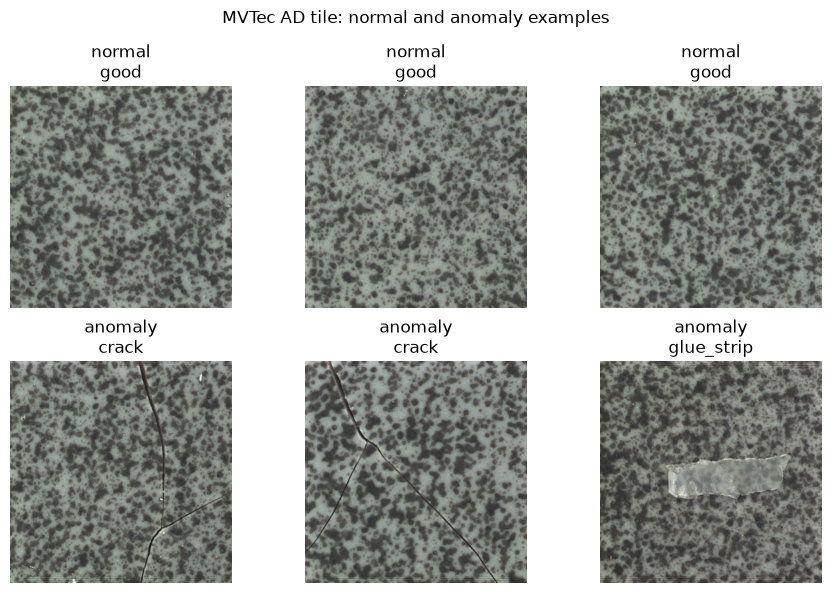

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

N_EXAMPLES = 3

normal_rows = rows_df[
    rows_df["split"] == "validation_good"
].head(N_EXAMPLES)

anomaly_rows = rows_df[
    rows_df["split"] == "validation_anomaly"
].head(N_EXAMPLES)

fig, axes = plt.subplots(
    2,
    N_EXAMPLES,
    figsize=(3 * N_EXAMPLES, 6)
)

for col, row in enumerate(normal_rows.itertuples()):
    img = Image.open(MVTEC_ROOT / row.path).convert("RGB")
    axes[0, col].imshow(img)
    axes[0, col].set_title(f"normal\n{row.defect_type}")
    axes[0, col].axis("off")

for col, row in enumerate(anomaly_rows.itertuples()):
    img = Image.open(MVTEC_ROOT / row.path).convert("RGB")
    axes[1, col].imshow(img)
    axes[1, col].set_title(f"anomaly\n{row.defect_type}")
    axes[1, col].axis("off")

fig.suptitle("MVTec AD tile: normal and anomaly examples")
fig.tight_layout()
plt.show()

## 3. Feature extraction

We extract features from the images and convert them into a form that is easy to cluster.

1. Convert each image into a feature vector with MobileNetV2
2. Standardize with StandardScaler and reduce dimensionality with PCA
3. Cluster the normal data with KMeans

Afterwards we cluster the same normal data with qklearn as well, and compare the results.

Features are computed on the first run and saved to `cache`; later runs reuse them.


### 3.1 Baseline settings

Define the baseline settings used for the preprocessing, clustering and anomaly detection that follow.


In [4]:
# Baseline settings used in this tutorial
pipeline_config = {
    "standardize": True,
    "l2_normalize": False,
    "pca_dim": 16,
    "pca_whiten": False,
    "score_mode": "nearest",
    "center_mode": "medoid",
    "scoring_metric": "euclidean",
    "threshold_mode": "percentile",
    "threshold_param": 95,
    "qklearn_metric": "euclidean",
    "qklearn_scaling": "normal",
    "n_clusters": 3,
    "size_constraint_mode": "none",
    "size_constraint_max_fraction": 1.0,
    "n_representative_samples": 60,
}

# Random seed for the data split and sample selection
SPLIT_SEED = 42

print("pipeline_config:")
for key, value in pipeline_config.items():
    print(f"  {key}: {value}")

print(f"SPLIT_SEED: {SPLIT_SEED}")

pipeline_config:
  standardize: True
  l2_normalize: False
  pca_dim: 16
  pca_whiten: False
  score_mode: nearest
  center_mode: medoid
  scoring_metric: euclidean
  threshold_mode: percentile
  threshold_param: 95
  qklearn_metric: euclidean
  qklearn_scaling: normal
  n_clusters: 3
  size_constraint_mode: none
  size_constraint_max_fraction: 1.0
  n_representative_samples: 60
SPLIT_SEED: 42


### 3.2 Feature extraction with MobileNetV2

Each image is fed to MobileNetV2 and converted into a 1280-dimensional feature vector.

On the first run the features are computed and saved to `cache`; on later runs the saved features are reused.


In [5]:
import hashlib
import json

import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Feature extraction settings for MobileNetV2
FEATURE_CONFIG = {
    "backbone": "mobilenet_v2",
    "pooling": "avg",
    "image_size": [224, 224],
}

FEATURE_CONFIG_HASH = hashlib.sha256(
    json.dumps(FEATURE_CONFIG, sort_keys=True).encode("utf-8")
).hexdigest()[:16]

BATCH_SIZE = 32


def extract_or_load_features(
    df,
    manifest_hash,
    feature_config_hash,
    cache_dir,
    mvtec_root_path,
):
    """Get the MobileNetV2 features. Reuse the cache if there is one."""

    cache_path = (
        cache_dir
        / f"features_{manifest_hash}_{feature_config_hash}.npz"
    )

    cached = {}

    # Load the existing cache
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as data:
            cached = dict(
                zip(
                    data["sample_ids"].tolist(),
                    data["features"],
                )
            )

        print(f"Feature cache loaded: {cache_path.name}")

    rows_to_extract = df[
        ~df["sample_id"].isin(cached.keys())
    ]

    # Extract features only for images that are not in the cache
    if len(rows_to_extract) > 0:
        from tensorflow.keras.applications.mobilenet_v2 import (
            MobileNetV2,
            preprocess_input,
        )
        from tensorflow.keras.preprocessing.image import (
            img_to_array,
            load_img,
        )

        print(
            f"Extracting features from "
            f"{len(rows_to_extract)} images..."
        )

        model = MobileNetV2(
            input_shape=(224, 224, 3),
            include_top=False,
            weights="imagenet",
            pooling="avg",
        )

        rows_list = list(rows_to_extract.itertuples())

        for start in range(0, len(rows_list), BATCH_SIZE):
            batch_rows = rows_list[
                start:start + BATCH_SIZE
            ]

            batch = np.stack(
                [
                    preprocess_input(
                        img_to_array(
                            load_img(
                                mvtec_root_path / row.path,
                                target_size=(224, 224),
                            )
                        )
                    )
                    for row in batch_rows
                ]
            )

            batch_features = model.predict(
                batch,
                verbose=0,
            )

            for row, feature in zip(
                batch_rows,
                batch_features,
            ):
                cached[row.sample_id] = feature

            print(
                f"  processed: "
                f"{min(start + BATCH_SIZE, len(rows_list))}"
                f"/{len(rows_list)}"
            )

        # Save the features
        cache_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        sample_ids = list(cached.keys())

        np.savez(
            cache_path,
            sample_ids=np.array(sample_ids),
            features=np.stack(
                [cached[sid] for sid in sample_ids]
            ),
        )

        print(f"Feature cache saved: {cache_path.name}")

    return cached


t0 = time.monotonic()

features_by_id = extract_or_load_features(
    rows_df,
    current_manifest_hash,
    FEATURE_CONFIG_HASH,
    CACHE_DIR,
    MVTEC_ROOT,
)

_timings["feature_extraction"] = (
    time.monotonic() - t0
)

print(
    f"Feature extraction time: "
    f"{_timings['feature_extraction']:.1f} sec"
)

Feature cache loaded: features_73d8a0971253998fd5cd111456f435e803722dba1e3bde80dd4d50ff131cbe81_d879676e7ee6b09a.npz
Feature extraction time: 0.0 sec


### 3.3 Standardization and PCA

Standardize the extracted features with StandardScaler and reduce their dimensionality with PCA.

StandardScaler and PCA are fitted on `train_fit_good` only; for other data such as Validation, they are only applied as transformations.


In [6]:
def raw_features(df, split_name, features_by_id):
    split_rows = df[
        df["split"] == split_name
    ]

    return np.stack(
        [
            features_by_id[sample_id]
            for sample_id in split_rows["sample_id"]
        ]
    )


# Fit StandardScaler on the normal training data
train_raw = raw_features(
    rows_df,
    "train_fit_good",
    features_by_id,
)

scaler = StandardScaler().fit(train_raw)

# Fit PCA on the normal training data
pca = PCA(
    n_components=pipeline_config["pca_dim"],
    whiten=pipeline_config["pca_whiten"],
    random_state=0,
).fit(
    scaler.transform(train_raw)
)


def preprocess(split_name):
    x = raw_features(
        rows_df,
        split_name,
        features_by_id,
    )

    if pipeline_config["standardize"]:
        x = scaler.transform(x)

    return pca.transform(x)


train_fit = preprocess("train_fit_good")
calibration = preprocess("calibration_good")
validation_good = preprocess("validation_good")
validation_anomaly = preprocess("validation_anomaly")

validation_features = np.concatenate(
    [
        validation_good,
        validation_anomaly,
    ]
)

validation_labels = np.concatenate(
    [
        np.zeros(
            len(validation_good),
            dtype=int,
        ),
        np.ones(
            len(validation_anomaly),
            dtype=int,
        ),
    ]
)

print(f"train_fit shape: {train_fit.shape}")
print(
    f"validation_features shape: "
    f"{validation_features.shape}"
)

train_fit shape: (196, 16)
validation_features shape: (20, 16)


### 3.4 Visualize the features

To look at the distribution of the features, we project them to two dimensions with PCA.

This 2D PCA is for display only and is not used for the actual anomaly decisions.


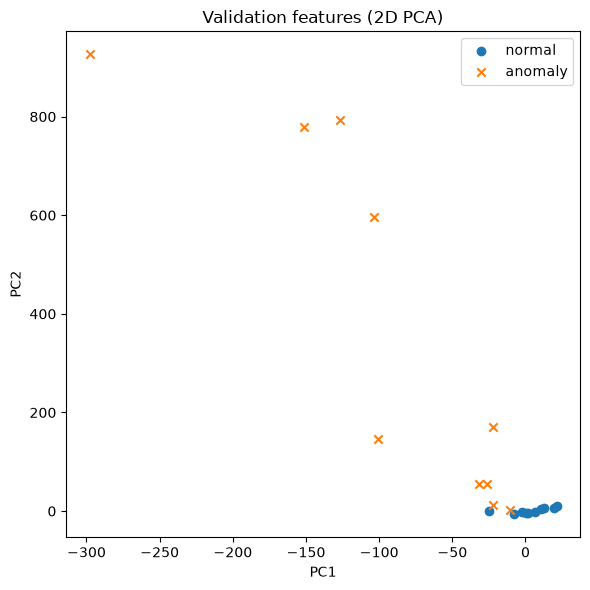

In [7]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Project the 16-dimensional features to 2D for visualization
viz_pca = PCA(
    n_components=2,
    random_state=0,
).fit(train_fit)

viz_validation_2d = viz_pca.transform(
    validation_features
)

normal_mask = validation_labels == 0

plt.figure(figsize=(6, 6))

plt.scatter(
    viz_validation_2d[normal_mask, 0],
    viz_validation_2d[normal_mask, 1],
    marker="o",
    label="normal",
)

plt.scatter(
    viz_validation_2d[~normal_mask, 0],
    viz_validation_2d[~normal_mask, 1],
    marker="x",
    label="anomaly",
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Validation features (2D PCA)")
plt.legend()
plt.tight_layout()
plt.show()

### 3.5 Clustering with KMeans

As a baseline for comparison, we apply KMeans to the normal data.

To keep the conditions the same as for qklearn, we use the same 60 samples.


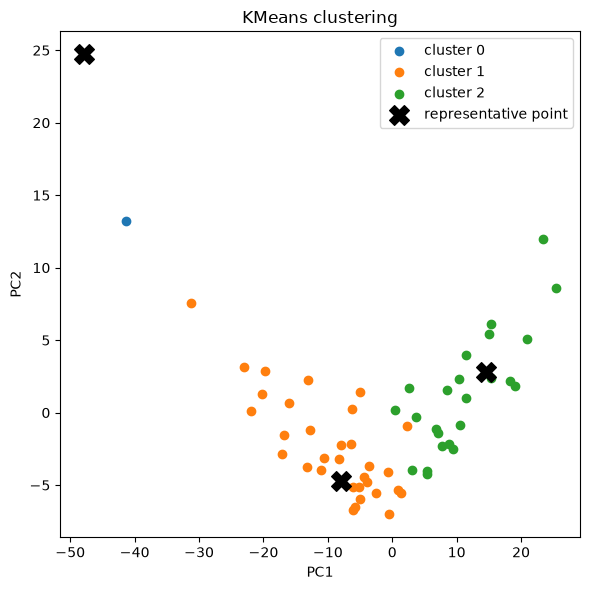

KMeans cluster assignments:
[2, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2, 1, 1, 2, 1, 1, 2, 1, 2, 1, 2, 2, 1, 1, 0, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 2, 2, 2, 1, 0, 1, 2, 1, 1, 2, 1, 1, 2]


In [8]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

# Select the same 60 samples as for qklearn from the normal training data
rng = np.random.RandomState(SPLIT_SEED)

fixed_subset_indices = np.sort(
    rng.choice(
        len(train_fit),
        size=pipeline_config["n_representative_samples"],
        replace=False,
    )
)

subset_features = train_fit[fixed_subset_indices]
subset_2d = viz_pca.transform(subset_features)

kmeans_labels = KMeans(
    n_clusters=pipeline_config["n_clusters"],
    random_state=SPLIT_SEED,
    n_init=10,
).fit_predict(subset_features)


# Compute the representative point of each cluster
kmeans_representative_points = []

for cluster_id in np.unique(kmeans_labels):
    members = subset_features[kmeans_labels == cluster_id]

    mean = members.mean(axis=0)

    distances = cdist(
        members,
        mean[None, :],
        metric=pipeline_config["scoring_metric"],
    ).ravel()

    kmeans_representative_points.append(
        members[np.argmin(distances)]
    )

kmeans_representative_points = np.stack(
    kmeans_representative_points
)

kmeans_reps_2d = viz_pca.transform(
    kmeans_representative_points
)


# Show the clustering result
plt.figure(figsize=(6, 6))

for cluster_id in np.unique(kmeans_labels):
    mask = kmeans_labels == cluster_id

    plt.scatter(
        subset_2d[mask, 0],
        subset_2d[mask, 1],
        label=f"cluster {cluster_id}",
    )

plt.scatter(
    kmeans_reps_2d[:, 0],
    kmeans_reps_2d[:, 1],
    c="black",
    marker="X",
    s=200,
    label="representative point",
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans clustering")
plt.legend()
plt.tight_layout()
plt.show()

print("KMeans cluster assignments:")
print(kmeans_labels.tolist())

## 4. Clustering with qklearn

In the previous chapter we split the normal data into three clusters with KMeans.
Here we cluster the same 60 samples with qklearn.

qklearn treats clustering as a combinatorial optimization problem called
**QUBO (Quadratic Unconstrained Binary Optimization)**.

A QUBO is an optimization problem that searches for a better combination
using variables that take the value 0 or 1.

Below, we run clustering with qklearn
and look at how it differs from KMeans.


### 4.1 Run clustering with qklearn

We run clustering with qklearn on the same 60 samples as in the previous chapter.

qklearn works as follows:

1. Load the data
2. Build the clustering problem as a QUBO
3. Solve the QUBO to obtain the cluster assignment

The QUBO and the clustering result obtained here are also used in the Qudas checks later.


In [9]:
import os
from datetime import timedelta

import numpy as np
from amplify import AmplifyAEClient
from qklearn.cluster import CombinatorialClustering


def build_amplify_client():
    """Create a client that connects to the cloud version of Amplify (Amplify AE v1)."""

    # Read the API token from an environment variable (never write it in the notebook)
    # Free token: https://amplify.fixstars.com/register
    # Note: AMPLIFY_TOKEN is a variable name chosen for this notebook (the SDK does not read it automatically)
    token = os.environ.get("AMPLIFY_TOKEN")

    if not token:
        raise RuntimeError(
            "Amplify API token not found. "
            "Set the environment variable AMPLIFY_TOKEN "
            "before starting Jupyter."
        )

    client = AmplifyAEClient()
    client.token = token

    # Time limit for a single solve
    client.parameters.time_limit_ms = timedelta(milliseconds=1000)

    # Do not specify the number of GPUs (num_gpus); leave it to the engine's default

    return client

    # ------------------------------------------------------------------
    # [When running on ABCI-Q]
    # ABCI-Q provides Amplify AE v0.8.8, so AmplifyAEClient
    # (the Amplify SDK v1 API) cannot be used. Instead of the AmplifyAEClient part above,
    # use the FixstarsClient below.
    # Official documentation (Japanese): https://g-quat-abciq.github.io/abciq-docs/ja/apps/amplify-ae/
    #
    # 1) Start an interactive job on a compute node (solving is only possible on compute nodes)
    #      qsub -l rt_QA=1 -W group_list=<group_name> -I
    # 2) Start the Amplify AE server on the compute node
    #      module load cuda/12.6/12.6.2
    #      /usr/local/sbin/fa_start
    # 3) Replace the body of build_amplify_client() as follows
    #      from amplify import FixstarsClient
    #
    #      client = FixstarsClient()
    #      client.url = "http://localhost:1080"  # On System H, specify localhost
    #      client.parameters.num_gpus = 4        # Number of GPUs used with rt_QA=1
    #      client.parameters.timeout = timedelta(milliseconds=1000)
    #      return client
    #    (The official page does not mention an API token)
    # ------------------------------------------------------------------


def run_qklearn(
    features,
    n_clusters,
    metric,
    scaling,
    max_attempts=2,
):
    """Run clustering with qklearn."""

    last_error = None

    for attempt in range(1, max_attempts + 1):
        client = build_amplify_client()

        clustering = CombinatorialClustering(
            n_clusters=n_clusters
        )

        clustering.fit(features)

        clustering.set_qubo(
            metric=metric,
            scaling=scaling,
        )

        try:
            cluster_labels = clustering.predict(client)

            qubo_matrix = np.asarray(
                clustering.indexed_qubo,
                dtype=float,
            )

            solution = np.asarray(
                clustering.solution,
                dtype=int,
            )

            energy = float(
                clustering.result.best.objective
            )

            return (
                cluster_labels,
                attempt,
                energy,
                qubo_matrix,
                solution,
            )

        except RuntimeError as error:
            last_error = error

    raise RuntimeError(
        f"qklearn clustering failed: {last_error}"
    )


t0 = time.monotonic()

labels_c, attempts, energy, qubo_matrix, solution = run_qklearn(
    subset_features,
    n_clusters=pipeline_config["n_clusters"],
    metric=pipeline_config["qklearn_metric"],
    scaling=pipeline_config["qklearn_scaling"],
)

_timings["qklearn_chapter4"] = time.monotonic() - t0

cluster_assignments_c = np.asarray(labels_c)

print("cluster assignments:")
print(cluster_assignments_c.tolist())

print(f"\nQUBO energy: {energy}")
print(f"Amplify calls: {attempts}")
print(
    f"Execution time: "
    f"{_timings['qklearn_chapter4']:.1f} sec"
)

2026-11-09 19:34:05 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.


cluster assignments:
[0, 0, 2, 0, 0, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 2, 2, 1, 0, 2, 2, 0, 0, 2, 0, 0, 2, 0, 1, 1, 2, 2, 1, 1, 1, 0, 2, 0, 2, 1, 1, 2, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 2, 1, 1, 2, 0, 0, 0]

QUBO energy: -3274.138834767599
Amplify calls: 1
Execution time: 4.1 sec


### 4.2 Representative point of each cluster

We choose one representative point for each cluster.

In this tutorial, the representative point is the actual data point closest to the mean of the cluster.

The anomaly score is computed as the distance from the input to the nearest representative point.
The larger the distance, the further the input is judged to be from the normal data.


In [10]:
from scipy.spatial.distance import cdist

def representative_points(features, cluster_labels, mode, metric):
    points = []

    for cluster_id in np.unique(cluster_labels):
        members = features[cluster_labels == cluster_id]

        if mode == "mean":
            points.append(members.mean(axis=0))

        else:
            mean = members.mean(axis=0)
            distances = cdist(
                members,
                mean[None, :],
                metric=metric,
            ).ravel()

            points.append(
                members[np.argmin(distances)]
            )

    return np.stack(points)


representative_points_c = representative_points(
    subset_features,
    cluster_assignments_c,
    pipeline_config["center_mode"],
    pipeline_config["scoring_metric"],
)

reps_c_2d = viz_pca.transform(
    representative_points_c
)

# Anomaly scores of the calibration data
calibration_scores = cdist(
    calibration,
    representative_points_c,
    metric=pipeline_config["scoring_metric"],
).min(axis=1)

print(
    f"representative points: "
    f"{len(representative_points_c)}"
)

print(
    "example anomaly scores:",
    calibration_scores[:5].round(3).tolist(),
)

representative points: 3
example anomaly scores: [23.168, 17.449, 9.692, 15.747, 15.347]


### 4.3 Clustering result of qklearn

We show the qklearn clustering result for the 60 samples
on the 2D PCA used for visualization.

The representative point of each cluster is shown as well.


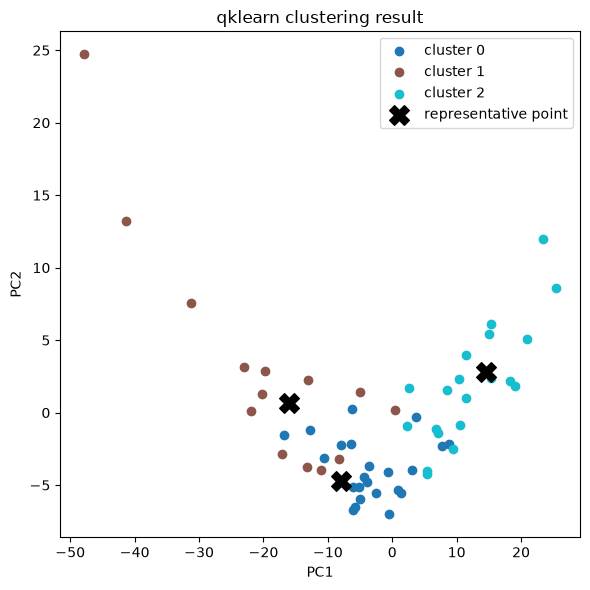

In [11]:
fig = plt.figure(figsize=(6, 6))

cluster_ids = np.unique(cluster_assignments_c)
colors = plt.cm.tab10(
    np.linspace(0, 1, len(cluster_ids))
)

for cluster_id, color in zip(cluster_ids, colors):
    mask = cluster_assignments_c == cluster_id

    plt.scatter(
        subset_2d[mask, 0],
        subset_2d[mask, 1],
        color=color,
        label=f"cluster {cluster_id}",
    )

# Representative point of each cluster
plt.scatter(
    reps_c_2d[:, 0],
    reps_c_2d[:, 1],
    c="black",
    marker="X",
    s=200,
    label="representative point",
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("qklearn clustering result")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Converting and solving the QUBO with Qudas

We use Qudas to convert the QUBO built by qklearn in Chapter 4 into other formats.

Here we express the same QUBO in three forms:

- QUBO matrix
- dimod BQM
- Amplify Poly

and confirm that the energy of the same solution is identical in all of them.

This confirms that Qudas lets us handle a QUBO across different libraries.


### 5.1 Converting the QUBO format with Qudas

We use Qudas to convert the QUBO built by qklearn in Chapter 4 into other formats.

We compute the energy of the same solution in

- the QUBO matrix
- the dimod BQM
- the Amplify Poly

and confirm that the QUBO is treated as the same problem even after changing the format.


In [12]:
from qudas import QuData
import pandas as pd

# Solution obtained by qklearn
x = solution.astype(float)

# Compute the energy directly from the QUBO matrix
direct_energy = float(
    x @ qubo_matrix @ x
)

# Convert to a dimod BQM with Qudas
bqm = (
    QuData.input()
    .from_array(qubo_matrix)
    .to_dimod_bqm()
)

dimod_sample = {
    f"q_{i}": int(v)
    for i, v in enumerate(solution)
}

dimod_energy = float(
    bqm.energy(dimod_sample)
)

# Convert to an Amplify Poly with Qudas
poly = (
    QuData.input()
    .from_array(qubo_matrix)
    .to_amplify()
)

# Map q_0, q_1, ... to the positions in the solution
substitution = {
    var: int(
        solution[
            int(var.name.rsplit("_", 1)[-1])
        ]
    )
    for var in poly.variables
}

amplify_poly_energy = float(
    poly.substitute(substitution)
)

energy_table = pd.DataFrame(
    {
        "representation": [
            "qklearn",
            "QUBO matrix",
            "dimod BQM",
            "Amplify Poly",
        ],
        "energy": [
            energy,
            direct_energy,
            dimod_energy,
            amplify_poly_energy,
        ],
    }
).set_index("representation")

energy_table

,energy
representation,
qklearn,-3274.138835
QUBO matrix,-3274.138835
dimod BQM,-3274.138835
Amplify Poly,-3274.138835


### 5.2 Solving the QUBO with Amplify and Neal

We solve the same QUBO with Amplify and with Neal (simulated annealing).

We compare the energies with the result obtained by qklearn, and confirm that different solvers can work on the same QUBO.


In [13]:
import neal
import pandas as pd

from amplify import solve


# -----------------------------
# Solve with Amplify
# -----------------------------
amplify_client = build_amplify_client()

t0 = time.monotonic()

amplify_result = solve(
    poly,
    amplify_client,
)

amplify_time = time.monotonic() - t0
amplify_best = amplify_result.best

amplify_energy = float(
    amplify_best.objective
)


# -----------------------------
# Solve with Neal
# -----------------------------
neal_sampler = neal.SimulatedAnnealingSampler()

t0 = time.monotonic()

neal_result = neal_sampler.sample(
    bqm,
    num_reads=100,
    seed=0,
)

neal_time = time.monotonic() - t0
neal_best = neal_result.first

neal_energy = float(
    neal_best.energy
)


# -----------------------------
# Compare the results
# -----------------------------
solver_table = pd.DataFrame(
    {
        "solver": [
            "qklearn",
            "Amplify",
            "Neal",
        ],
        "energy": [
            energy,
            amplify_energy,
            neal_energy,
        ],
        "time_sec": [
            _timings["qklearn_chapter4"],
            amplify_time,
            neal_time,
        ],
    }
).set_index("solver")

solver_table

2026-11-09 19:34:10 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.


,energy,time_sec
solver,,
qklearn,-3274.138835,4.125
Amplify,-3275.574088,4.797
Neal,-3247.730050,0.188


### 5.3 Compare the clustering results

We convert the solutions obtained by qklearn, Amplify and Neal into cluster assignments,
and compare the clustering results for the same 60 samples.

We also check how closely each result agrees with qklearn using ARI (Adjusted Rand Index).


qklearn vs KMeans ARI:  0.407
qklearn vs Amplify ARI: 0.626
qklearn vs Neal ARI:    -0.002


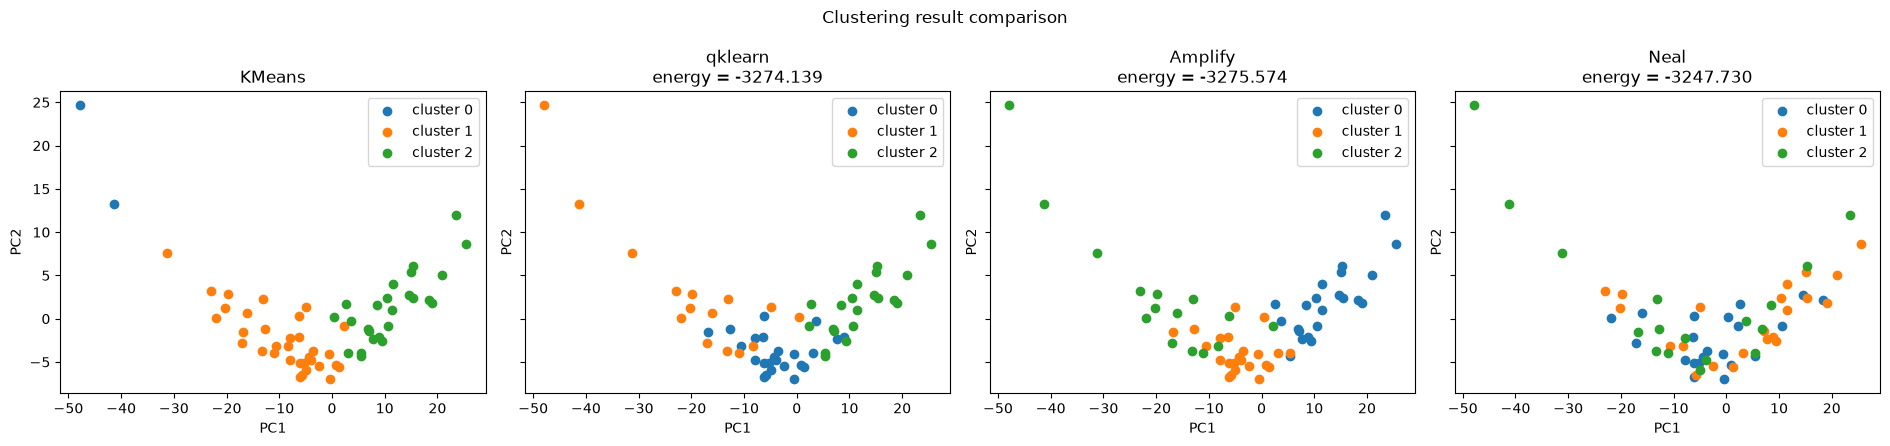

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

n_samples = len(subset_features)
n_clusters = pipeline_config["n_clusters"]


# Arrange the Amplify solution in the order q_0, q_1, ...
amplify_solution = np.zeros(len(solution), dtype=int)

for var, value in amplify_best.values.items():
    index = int(var.name.rsplit("_", 1)[-1])
    amplify_solution[index] = int(value)


# Arrange the Neal solution in the order q_0, q_1, ...
neal_solution = np.array(
    [
        int(neal_best.sample[f"q_{i}"])
        for i in range(len(solution))
    ],
    dtype=int,
)


def decode_solution(bits):
    matrix = bits.reshape(
        n_samples,
        n_clusters,
    )

    if not np.all(matrix.sum(axis=1) == 1):
        raise ValueError(
            "Invalid cluster assignment: "
            "a sample is not assigned to exactly one cluster."
        )

    return np.argmax(matrix, axis=1)


# Convert the QUBO solutions into cluster labels
qklearn_labels = decode_solution(solution)
amplify_labels = decode_solution(amplify_solution)
neal_labels = decode_solution(neal_solution)


# Agreement with qklearn
kmeans_ari = adjusted_rand_score(
    qklearn_labels,
    kmeans_labels,
)

amplify_ari = adjusted_rand_score(
    qklearn_labels,
    amplify_labels,
)

neal_ari = adjusted_rand_score(
    qklearn_labels,
    neal_labels,
)

print(f"qklearn vs KMeans ARI:  {kmeans_ari:.3f}")
print(f"qklearn vs Amplify ARI: {amplify_ari:.3f}")
print(f"qklearn vs Neal ARI:    {neal_ari:.3f}")


# Show the four methods side by side
results = [
    ("KMeans", kmeans_labels, None),
    ("qklearn", qklearn_labels, energy),
    ("Amplify", amplify_labels, amplify_energy),
    ("Neal", neal_labels, neal_energy),
]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(19, 4.5),
    sharex=True,
    sharey=True,
)

for ax, (name, labels, solver_energy) in zip(
    axes,
    results,
):

    for cluster_id in np.unique(labels):
        mask = labels == cluster_id

        ax.scatter(
            subset_2d[mask, 0],
            subset_2d[mask, 1],
            label=f"cluster {cluster_id}",
        )

    if solver_energy is None:
        ax.set_title(name)
    else:
        ax.set_title(
            f"{name}\nenergy = {solver_energy:.3f}"
        )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

fig.suptitle(
    "Clustering result comparison"
)

fig.tight_layout()
plt.show()

## 6. Evaluating the anomaly detection results

We perform anomaly detection using the representative points of the normal data obtained in Chapter 4.

For each image, the distance to the nearest representative point is its anomaly score.
The closer an image is to a representative point the more normal it is judged to be, and the farther away, the more anomalous.

First, we compute the anomaly score distribution of the normal images in `calibration_good`
and use its 95th percentile as the threshold separating normal from anomalous.

We then classify the Validation data with this threshold
and evaluate the anomaly detection performance.


### 6.1 Evaluate anomaly detection on Validation

We obtain the threshold, the 95th percentile of the anomaly scores of `calibration_good`.

We classify the Validation data as normal or anomalous with that threshold
and check metrics such as Recall, Precision and F1.


In [15]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Determine the threshold from the calibration data
threshold = float(
    np.percentile(
        calibration_scores,
        pipeline_config["threshold_param"],
    )
)

# Anomaly scores of the Validation data
validation_scores = cdist(
    validation_features,
    representative_points_c,
    metric=pipeline_config["scoring_metric"],
).min(axis=1)

# Anomalous if above the threshold
predictions = (
    validation_scores > threshold
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    validation_labels,
    predictions,
    labels=[0, 1],
).ravel()

# Evaluation metrics
validation_metrics = {
    "Recall": recall_score(
        validation_labels,
        predictions,
        zero_division=0,
    ),
    "Precision": precision_score(
        validation_labels,
        predictions,
        zero_division=0,
    ),
    "F1": f1_score(
        validation_labels,
        predictions,
        zero_division=0,
    ),
    "FPR": (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0.0
    ),
    "ROC-AUC": roc_auc_score(
        validation_labels,
        validation_scores,
    ),
    "PR-AUC": average_precision_score(
        validation_labels,
        validation_scores,
    ),
}

print(f"threshold: {threshold:.3f}")
print(f"TP={tp}, FP={fp}, TN={tn}, FN={fn}")
print()

for name, value in validation_metrics.items():
    print(f"{name}: {value:.3f}")

threshold: 22.643
TP=10, FP=1, TN=9, FN=0

Recall: 1.000
Precision: 0.909
F1: 0.952
FPR: 0.100
ROC-AUC: 0.980
PR-AUC: 0.981


Validation is used to check the settings and the threshold.

After that, we apply them to the Test data without changing anything
and check the performance on unseen data.

We do not readjust the settings or the threshold after looking at the Test results.


### 6.2 Visualize the Validation results

We show the distribution of anomaly scores on the Validation data together with the threshold.

We also check the normal/anomalous decisions with a confusion matrix.


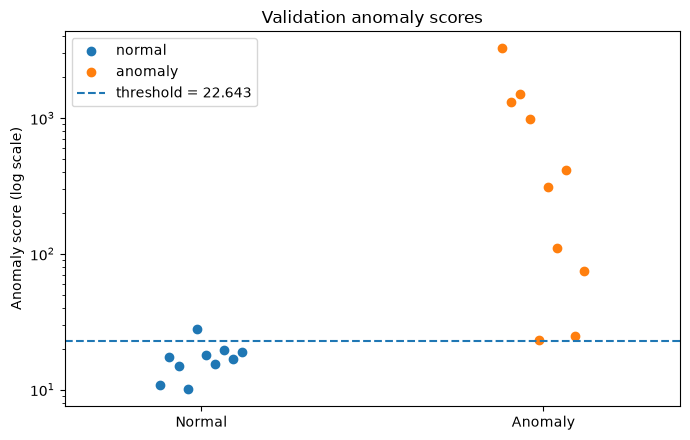

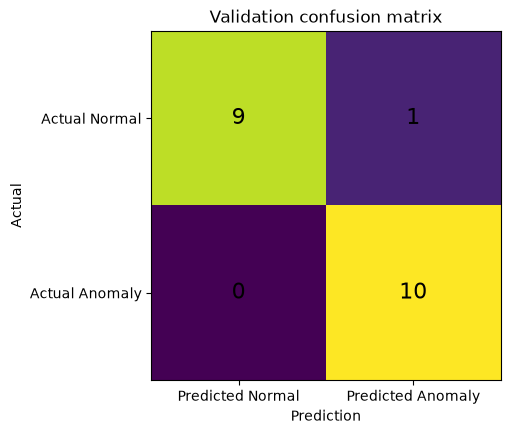

In [16]:
# Show the Validation anomaly scores in two groups, Normal / Anomaly
normal_scores = validation_scores[validation_labels == 0]
anomaly_scores = validation_scores[validation_labels == 1]

normal_x = np.linspace(-0.12, 0.12, len(normal_scores))
anomaly_x = np.linspace(0.88, 1.12, len(anomaly_scores))

plt.figure(figsize=(7, 4.5))

plt.scatter(
    normal_x,
    normal_scores,
    label="normal",
)

plt.scatter(
    anomaly_x,
    anomaly_scores,
    label="anomaly",
)

plt.axhline(
    threshold,
    linestyle="--",
    label=f"threshold = {threshold:.3f}",
)

# Log scale
plt.yscale("log")

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"],
)

plt.xlim(-0.4, 1.4)
plt.ylabel("Anomaly score (log scale)")
plt.title("Validation anomaly scores")
plt.legend()
plt.tight_layout()
plt.show()


# Confusion matrix of Validation
cm = confusion_matrix(
    validation_labels,
    predictions,
    labels=[0, 1],
)

fig, ax = plt.subplots(figsize=(5, 4.5))

ax.imshow(cm)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16,
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Predicted Normal",
    "Predicted Anomaly",
])

ax.set_yticklabels([
    "Actual Normal",
    "Actual Anomaly",
])

ax.set_xlabel("Prediction")
ax.set_ylabel("Actual")
ax.set_title("Validation confusion matrix")

fig.tight_layout()
plt.show()

### 6.3 Final evaluation on the Test data

We apply the settings fixed during Validation, without any change,
to the Test data, which has not been used for tuning so far.

We compute the anomaly scores of the Test data
and classify them as normal or anomalous with the same threshold used for Validation.

We do not readjust the settings or the threshold after looking at the Test results.

#### Visualize the Test results

We show the anomaly scores of the Test data together with the threshold.

Using the threshold fixed on Validation as it is,
we check how the normal and anomalous Test data were classified.


In [17]:
# Apply the already-fitted preprocessing to the Test data as it is
test_good = preprocess("test_good")
test_anomaly = preprocess("test_anomaly")

# Combine the Test data
test_features = np.concatenate(
    [
        test_good,
        test_anomaly,
    ]
)

test_labels = np.concatenate(
    [
        np.zeros(
            len(test_good),
            dtype=int,
        ),
        np.ones(
            len(test_anomaly),
            dtype=int,
        ),
    ]
)


# Use the distance to the representative points from Chapter 4 as the anomaly score
test_scores = cdist(
    test_features,
    representative_points_c,
    metric=pipeline_config["scoring_metric"],
).min(axis=1)


# Use the threshold fixed during Validation as it is
test_predictions = (
    test_scores > threshold
).astype(int)


# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1],
).ravel()


# Evaluation metrics
test_metrics = {
    "Recall": recall_score(
        test_labels,
        test_predictions,
        zero_division=0,
    ),
    "Precision": precision_score(
        test_labels,
        test_predictions,
        zero_division=0,
    ),
    "F1": f1_score(
        test_labels,
        test_predictions,
        zero_division=0,
    ),
    "FPR": (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0.0
    ),
    "ROC-AUC": roc_auc_score(
        test_labels,
        test_scores,
    ),
    "PR-AUC": average_precision_score(
        test_labels,
        test_scores,
    ),
}

print(f"threshold: {threshold:.3f}")
print(f"TP={tp}, FP={fp}, TN={tn}, FN={fn}")
print()

for name, value in test_metrics.items():
    print(f"{name}: {value:.3f}")



threshold: 22.643
TP=8, FP=0, TN=10, FN=2

Recall: 0.800
Precision: 1.000
F1: 0.889
FPR: 0.000
ROC-AUC: 0.970
PR-AUC: 0.977


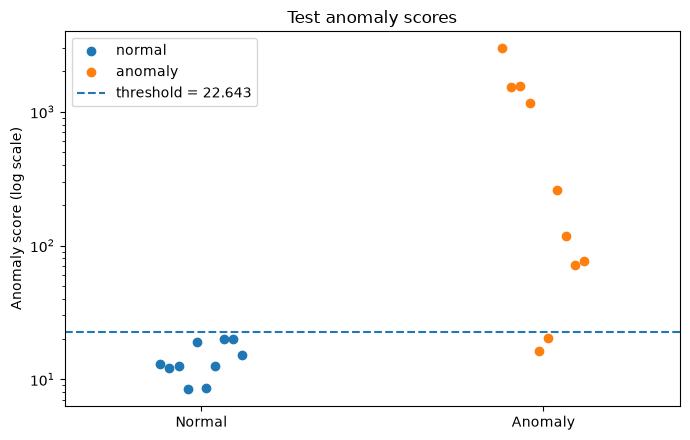

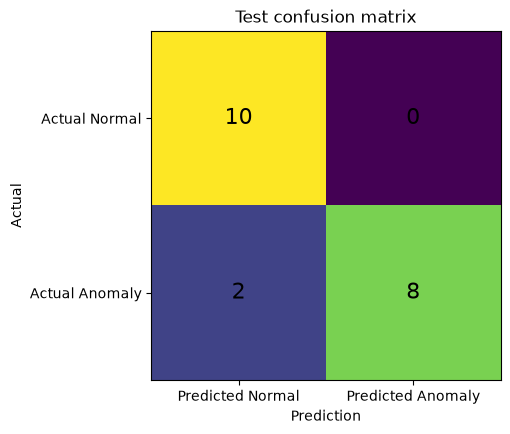

In [18]:
# Show the Test anomaly scores in two groups, Normal / Anomaly
test_normal_scores = test_scores[test_labels == 0]
test_anomaly_scores = test_scores[test_labels == 1]

normal_x = np.linspace(-0.12, 0.12, len(test_normal_scores))
anomaly_x = np.linspace(0.88, 1.12, len(test_anomaly_scores))

plt.figure(figsize=(7, 4.5))

plt.scatter(
    normal_x,
    test_normal_scores,
    label="normal",
)

plt.scatter(
    anomaly_x,
    test_anomaly_scores,
    label="anomaly",
)

plt.axhline(
    threshold,
    linestyle="--",
    label=f"threshold = {threshold:.3f}",
)

plt.yscale("log")

plt.xticks(
    [0, 1],
    ["Normal", "Anomaly"],
)

plt.xlim(-0.4, 1.4)
plt.ylabel("Anomaly score (log scale)")
plt.title("Test anomaly scores")
plt.legend()
plt.tight_layout()
plt.show()


# Confusion matrix of Test
test_cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1],
)

fig, ax = plt.subplots(figsize=(5, 4.5))

ax.imshow(test_cm)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(test_cm[i, j]),
            ha="center",
            va="center",
            fontsize=16,
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Predicted Normal",
    "Predicted Anomaly",
])

ax.set_yticklabels([
    "Actual Normal",
    "Actual Anomaly",
])

ax.set_xlabel("Prediction")
ax.set_ylabel("Actual")
ax.set_title("Test confusion matrix")

fig.tight_layout()
plt.show()

### 6.4 Compare anomaly detection performance across clustering methods

Using the clustering results of KMeans, qklearn, Amplify and Neal,
we compare the anomaly detection performance on the Test data.

For each method, the threshold is determined separately from `calibration_good`,
and Recall, Precision, F1 and so on are evaluated on the same Test data.


In [19]:
import pandas as pd

# Representative points of each method
method_representatives = {
    "KMeans": kmeans_representative_points,

    "qklearn": representative_points(
        subset_features,
        qklearn_labels,
        pipeline_config["center_mode"],
        pipeline_config["scoring_metric"],
    ),

    "Amplify": representative_points(
        subset_features,
        amplify_labels,
        pipeline_config["center_mode"],
        pipeline_config["scoring_metric"],
    ),

    "Neal": representative_points(
        subset_features,
        neal_labels,
        pipeline_config["center_mode"],
        pipeline_config["scoring_metric"],
    ),
}

comparison_results = []

for method_name, reps in method_representatives.items():

    # Determine a threshold specific to this method from calibration_good
    calibration_scores_method = cdist(
        calibration,
        reps,
        metric=pipeline_config["scoring_metric"],
    ).min(axis=1)

    method_threshold = float(
        np.percentile(
            calibration_scores_method,
            pipeline_config["threshold_param"],
        )
    )

    # Anomaly scores of the Test data
    scores = cdist(
        test_features,
        reps,
        metric=pipeline_config["scoring_metric"],
    ).min(axis=1)

    predictions_method = (
        scores > method_threshold
    ).astype(int)

    tn_m, fp_m, fn_m, tp_m = confusion_matrix(
        test_labels,
        predictions_method,
        labels=[0, 1],
    ).ravel()

    comparison_results.append({
        "Method": method_name,
        "Threshold": method_threshold,
        "Recall": recall_score(
            test_labels,
            predictions_method,
            zero_division=0,
        ),
        "Precision": precision_score(
            test_labels,
            predictions_method,
            zero_division=0,
        ),
        "F1": f1_score(
            test_labels,
            predictions_method,
            zero_division=0,
        ),
        "FPR": (
            fp_m / (fp_m + tn_m)
            if (fp_m + tn_m) > 0
            else 0.0
        ),
        "TP": tp_m,
        "FP": fp_m,
        "TN": tn_m,
        "FN": fn_m,
    })

comparison_df = pd.DataFrame(
    comparison_results
)

display(
    comparison_df.round({
        "Threshold": 3,
        "Recall": 3,
        "Precision": 3,
        "F1": 3,
        "FPR": 3,
    })
)

,Method,Threshold,Recall,Precision,F1,FPR,TP,FP,TN,FN
0,KMeans,24.805,0.8,1.0,0.889,0.0,8,0,10,2
1,qklearn,22.643,0.8,1.0,0.889,0.0,8,0,10,2
2,Amplify,22.643,0.8,1.0,0.889,0.0,8,0,10,2
3,Neal,28.637,0.8,1.0,0.889,0.0,8,0,10,2


### 6.5 Summary

We checked the anomaly detection performance using Validation and Test.

The clustering results differed between KMeans, qklearn, Amplify and Neal,
but on this Test data the final anomaly detection results were the same.

In the next chapter we search for hyperparameters with SWIFT-FMQA.


## 7. Parameter search with SWIFT-FMQA

Here we search for the hyperparameters of the qklearn pipeline
using SWIFT-FMQA.

Instead of trying every combination one after another,
we predict which setting is worth trying next
from the settings tried so far and their evaluation results.

SWIFT-FMQA uses a Factorization Machine (FM) as a surrogate model.
The FM learns the relationship between the parameters tried so far and their evaluation results,
and is used to choose the next candidate to evaluate.

In this chapter we actually compare the following two search methods.

- SWIFT-FMQA: choose the next candidate using the results so far
- Random Search: choose candidates at random

For each candidate we run clustering with qklearn and evaluate it on Validation,
and look for the setting that minimizes `objective = 1 - Validation F1`.


### 7.1 Hands-on search space and the objective

To keep the search time short in this hands-on tutorial,
we narrow the search to 4 hyperparameters and 36 combinations.

| Axis | Candidate values |
|---|---|
| pca_dim | 16, 32, 64 |
| center_mode | mean, medoid |
| n_clusters | 2, 3, 4 |
| n_representative_samples | 30, 60 |

The following settings are fixed.

- threshold: percentile 95
- qklearn metric: euclidean
- qklearn scaling: normal

For each candidate we compute the Validation F1, and look for the setting that minimizes

`objective = 1 - Validation F1`.


In [20]:
import itertools

# Parameters searched in this hands-on tutorial
HANDSON_CHOICES = {
    "pca_dim": [16, 32, 64],
    "center_mode": ["mean", "medoid"],
    "n_clusters": [2, 3, 4],
    "n_representative_samples": [30, 60],
}

HANDSON_AXES = (
    "pca_dim",
    "center_mode",
    "n_clusters",
    "n_representative_samples",
)

ALL_HANDSON_COMBOS = [
    dict(zip(HANDSON_AXES, combo))
    for combo in itertools.product(
        *(HANDSON_CHOICES[axis] for axis in HANDSON_AXES)
    )
]

print(
    f"Handson search space: "
    f"{len(ALL_HANDSON_COMBOS)} configurations"
)

HANDSON_SEED = SPLIT_SEED


# Cache the preprocessing results for each PCA dimension
_pca_cache = {}


def select_representative_indices(
    n_total,
    n_representative,
    seed,
):
    """Select the representative samples using the same seed."""

    rng = np.random.RandomState(seed)

    indices = rng.choice(
        n_total,
        size=n_representative,
        replace=False,
    )

    return np.sort(indices)


def get_preprocessed(pca_dim):
    """Preprocess with the given PCA dimension."""

    if pca_dim not in _pca_cache:

        # train_fit_good
        train_raw_h = raw_features(
            rows_df,
            "train_fit_good",
            features_by_id,
        )

        # Fit PCA on the normal training data only
        pca_h = PCA(
            n_components=pca_dim,
            whiten=pipeline_config["pca_whiten"],
            random_state=0,
        ).fit(
            scaler.transform(train_raw_h)
        )

        def transform_split(split_name):
            x = raw_features(
                rows_df,
                split_name,
                features_by_id,
            )

            x = scaler.transform(x)

            return pca_h.transform(x)

        train_fit_h = transform_split(
            "train_fit_good"
        )

        calibration_h = transform_split(
            "calibration_good"
        )

        validation_good_h = transform_split(
            "validation_good"
        )

        validation_anomaly_h = transform_split(
            "validation_anomaly"
        )

        validation_features_h = np.concatenate([
            validation_good_h,
            validation_anomaly_h,
        ])

        validation_labels_h = np.concatenate([
            np.zeros(
                len(validation_good_h),
                dtype=int,
            ),
            np.ones(
                len(validation_anomaly_h),
                dtype=int,
            ),
        ])

        _pca_cache[pca_dim] = (
            train_fit_h,
            calibration_h,
            validation_features_h,
            validation_labels_h,
        )

    return _pca_cache[pca_dim]


def evaluate_candidate(params):
    """Evaluate one parameter setting on Validation."""

    (
        train_fit_h,
        calibration_h,
        validation_features_h,
        validation_labels_h,
    ) = get_preprocessed(
        params["pca_dim"]
    )

    # Select the normal samples used for clustering
    subset_indices = select_representative_indices(
        len(train_fit_h),
        params["n_representative_samples"],
        HANDSON_SEED,
    )

    subset_features_h = train_fit_h[
        subset_indices
    ]

    # Cluster with qklearn + Amplify
    labels, attempts, energy, _, _ = run_qklearn(
        subset_features_h,
        n_clusters=params["n_clusters"],
        metric=pipeline_config["qklearn_metric"],
        scaling=pipeline_config["qklearn_scaling"],
    )

    # Representative point of each cluster
    reps = representative_points(
        subset_features_h,
        np.asarray(labels),
        params["center_mode"],
        pipeline_config["scoring_metric"],
    )

    # Determine the threshold from calibration
    calibration_scores_h = cdist(
        calibration_h,
        reps,
        metric=pipeline_config["scoring_metric"],
    ).min(axis=1)

    threshold_h = float(
        np.percentile(
            calibration_scores_h,
            pipeline_config["threshold_param"],
        )
    )

    # Anomaly scores of Validation
    validation_scores_h = cdist(
        validation_features_h,
        reps,
        metric=pipeline_config["scoring_metric"],
    ).min(axis=1)

    predictions_h = (
        validation_scores_h > threshold_h
    ).astype(int)

    f1 = float(
        f1_score(
            validation_labels_h,
            predictions_h,
            zero_division=0,
        )
    )

    recall = float(
        recall_score(
            validation_labels_h,
            predictions_h,
            zero_division=0,
        )
    )

    precision = float(
        precision_score(
            validation_labels_h,
            predictions_h,
            zero_division=0,
        )
    )

    return {
        "f1": f1,
        "recall": recall,
        "precision": precision,
        "objective": 1.0 - f1,
        "energy": energy,
        "amplify_calls": attempts,
    }

Handson search space: 36 configurations


### 7.2 Live search with SWIFT-FMQA

With SWIFT-FMQA, we evaluate 15 candidates
chosen from the 36-point search space.

For each candidate we show

- the parameter setting
- the Validation F1
- the objective
- the best F1 so far

SWIFT-FMQA updates the surrogate model from the results evaluated so far
and uses it to choose the next candidate.

#### A note on the random seed

The random seed (`SEARCH_SEED = 4`) of SWIFT-FMQA and Random Search
was chosen after trying several seeds, so that
"how FMQA improves after the first 3 random evaluations" is easy to see
(only the Validation F1 was used to choose it; the Test data was not used).

In practice, the results change with the seed. With 14 seeds,
FMQA beat Random Search in 2, Random Search beat FMQA in 3, the results were the same in 7,
and FMQA stopped with an internal error in 2.
Please treat this figure as one example for explaining how the method works,
not as evidence that "FMQA is always better than Random Search".

Also, with the cloud version of Amplify a single solve may be cut off by the time limit,
so the evaluation values can change slightly even with the same seed,
and the curves differ somewhat from run to run.




In [21]:
import amplify_bbopt as bb

# Candidates already evaluated by SWIFT-FMQA
_fmqa_evaluated = {}

# History of newly evaluated candidates
_fmqa_log = []

N_FMQA_EVALUATIONS = 15

# Random seed for SWIFT-FMQA and Random Search (separate from HANDSON_SEED; see the note in 7.2 for why it was chosen)
SEARCH_SEED = 4
N_FMQA_INITIAL_RANDOM = 3
MAX_FMQA_SURROGATE_CALLS = 30


def decode_fmqa(
    pca_dim_idx,
    center_mode_idx,
    n_clusters_idx,
    n_rep_idx,
):
    """Convert the FMQA variables into the actual parameters."""

    return {
        "pca_dim":
            HANDSON_CHOICES["pca_dim"][
                int(round(pca_dim_idx))
            ],

        "center_mode":
            HANDSON_CHOICES["center_mode"][
                int(round(center_mode_idx))
            ],

        "n_clusters":
            HANDSON_CHOICES["n_clusters"][
                int(round(n_clusters_idx))
            ],

        "n_representative_samples":
            HANDSON_CHOICES[
                "n_representative_samples"
            ][
                int(round(n_rep_idx))
            ],
    }


@bb.blackbox
def fmqa_objective(
    pca_dim_idx=bb.DiscreteVariable(
        values=[0, 1, 2]
    ),
    center_mode_idx=bb.BinaryVariable(),
    n_clusters_idx=bb.DiscreteVariable(
        values=[0, 1, 2]
    ),
    n_rep_idx=bb.BinaryVariable(),
):

    params = decode_fmqa(
        pca_dim_idx,
        center_mode_idx,
        n_clusters_idx,
        n_rep_idx,
    )

    key = tuple(sorted(params.items()))

    # If it has already been evaluated, reuse the result
    if key in _fmqa_evaluated:
        return _fmqa_evaluated[key]["objective"]

    # Actually evaluate the new candidate
    try:
        result = evaluate_candidate(params)

    except RuntimeError:
        # If qklearn did not return a valid cluster assignment
        result = {
            "f1": 0.0,
            "recall": 0.0,
            "precision": 0.0,
            "objective": 1.0,
            "failed": True,
        }

    _fmqa_evaluated[key] = result

    best_objective = min(
        r["objective"]
        for r in _fmqa_evaluated.values()
    )

    _fmqa_log.append({
        "evaluation": len(_fmqa_log) + 1,
        "params": params,
        "f1": result["f1"],
        "objective": result["objective"],
        "best_so_far_f1": 1.0 - best_objective,
    })

    print(
        f"[FMQA {len(_fmqa_log)}/"
        f"{N_FMQA_EVALUATIONS}] "
        f"{params} "
        f"F1={result['f1']:.3f} "
        f"best={1.0 - best_objective:.3f}"
    )

    return result["objective"]


# Use the cloud version of Amplify (see the note in Chapter 4 when running on ABCI-Q)
fmqa_client = build_amplify_client()

fmqa_optimizer = bb.Optimizer(
    blackbox=fmqa_objective,
    trainer=bb.FMTrainer(),
    client=fmqa_client,
    seed=SEARCH_SEED,
)


print(
    f"SWIFT-FMQA search: "
    f"{N_FMQA_EVALUATIONS} evaluations"
)

t0 = time.monotonic()


# Evaluate the first 3 candidates at random
while len(_fmqa_log) < N_FMQA_INITIAL_RANDOM:
    fmqa_optimizer.add_random_training_data(
        num_data=1
    )


# Choose the next candidate using the FM surrogate model
surrogate_calls = 0

while (
    len(_fmqa_log) < N_FMQA_EVALUATIONS
    and
    surrogate_calls < MAX_FMQA_SURROGATE_CALLS
):

    surrogate_calls += 1

    fmqa_optimizer.optimize(
        num_iterations=1
    )


_timings["swift_fmqa"] = (
    time.monotonic() - t0
)


if len(_fmqa_log) < N_FMQA_EVALUATIONS:
    print(
        "Warning: "
        f"{len(_fmqa_log)}/"
        f"{N_FMQA_EVALUATIONS} "
        "distinct candidates evaluated."
    )


fmqa_history = pd.DataFrame(
    _fmqa_log
)

fmqa_history

[2026-11-09 19:34:13] [amplify_bbopt] [INFO] Random data sample: 1/1


SWIFT-FMQA search: 15 evaluations


2026-11-09 19:34:16 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.


[2026-11-09 19:34:16] [amplify_bbopt] [INFO] Random data sample: 1/1


[FMQA 1/15] {'pca_dim': 64, 'center_mode': 'medoid', 'n_clusters': 4, 'n_representative_samples': 60} F1=0.952 best=0.952


[2026-11-09 19:34:20] [amplify_bbopt] [INFO] Random data sample: 1/1


... (65 outputs left out)

[2026-11-09 19:35:57] [amplify_bbopt] [INFO]    objective: 4.762e-02


[2026-11-09 19:35:57] [amplify_bbopt] [INFO] current best: 0.000e+00


[FMQA 15/15] {'pca_dim': 32, 'center_mode': 'medoid', 'n_clusters': 2, 'n_representative_samples': 60} F1=0.952 best=1.000


,evaluation,params,f1,objective,best_so_far_f1
0,1,"{'pca_dim': 64, 'center_mode': 'medoid', 'n_cl...",0.952381,0.047619,0.952381
1,2,"{'pca_dim': 64, 'center_mode': 'medoid', 'n_cl...",0.952381,0.047619,0.952381
2,3,"{'pca_dim': 32, 'center_mode': 'medoid', 'n_cl...",0.952381,0.047619,0.952381
3,4,"{'pca_dim': 16, 'center_mode': 'mean', 'n_clus...",0.857143,0.142857,0.952381
4,5,"{'pca_dim': 64, 'center_mode': 'mean', 'n_clus...",0.833333,0.166667,0.952381
5,6,"{'pca_dim': 16, 'center_mode': 'medoid', 'n_cl...",0.900000,0.100000,0.952381
6,7,"{'pca_dim': 32, 'center_mode': 'mean', 'n_clus...",0.952381,0.047619,0.952381
7,8,"{'pca_dim': 32, 'center_mode': 'medoid', 'n_cl...",1.000000,0.000000,1.000000
8,9,"{'pca_dim': 64, 'center_mode': 'mean', 'n_clus...",0.869565,0.130435,1.000000
9,10,"{'pca_dim': 64, 'center_mode': 'mean', 'n_clus...",0.869565,0.130435,1.000000


### 7.3 Comparison with Random Search

For comparison with SWIFT-FMQA,
we choose 15 candidates at random from the same 36-point search space and evaluate them.

The number of evaluations and the Validation-based evaluation method are the same as for SWIFT-FMQA.


In [22]:
import random

random_log = []
N_RANDOM_EVALUATIONS = 15

# Make it reproducible with the same seed
random_rng = random.Random(SEARCH_SEED)

# Choose 15 of the 36 candidates without replacement
random_candidates = random_rng.sample(
    ALL_HANDSON_COMBOS,
    N_RANDOM_EVALUATIONS,
)

print(
    f"Random Search: "
    f"{N_RANDOM_EVALUATIONS} evaluations"
)

t0 = time.monotonic()

best_objective = None

for params in random_candidates:

    # Actually evaluate the candidate
    result = evaluate_candidate(params)

    if best_objective is None:
        best_objective = result["objective"]
    else:
        best_objective = min(
            best_objective,
            result["objective"],
        )

    random_log.append({
        "evaluation": len(random_log) + 1,
        "params": params,
        "f1": result["f1"],
        "objective": result["objective"],
        "best_so_far_f1": 1.0 - best_objective,
    })

    print(
        f"[Random {len(random_log)}/"
        f"{N_RANDOM_EVALUATIONS}] "
        f"{params} "
        f"F1={result['f1']:.3f} "
        f"best={1.0 - best_objective:.3f}"
    )


_timings["random_search"] = (
    time.monotonic() - t0
)

random_history = pd.DataFrame(
    random_log
)

random_history

Random Search: 15 evaluations


2026-11-09 19:36:00 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.


[Random 1/15] {'pca_dim': 32, 'center_mode': 'mean', 'n_clusters': 3, 'n_representative_samples': 60} F1=0.857 best=0.857


[Random 2/15] {'pca_dim': 32, 'center_mode': 'medoid', 'n_clusters': 2, 'n_representative_samples': 60} F1=0.952 best=0.952


[Random 3/15] {'pca_dim': 16, 'center_mode': 'medoid', 'n_clusters': 2, 'n_representative_samples': 30} F1=0.952 best=0.952


2026-11-09 19:36:18 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.


... (12 outputs left out)

2026-11-09 19:37:12 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.


[Random 14/15] {'pca_dim': 16, 'center_mode': 'medoid', 'n_clusters': 2, 'n_representative_samples': 60} F1=0.952 best=0.952


[Random 15/15] {'pca_dim': 32, 'center_mode': 'mean', 'n_clusters': 4, 'n_representative_samples': 30} F1=0.952 best=0.952


,evaluation,params,f1,objective,best_so_far_f1
0,1,"{'pca_dim': 32, 'center_mode': 'mean', 'n_clus...",0.857143,0.142857,0.857143
1,2,"{'pca_dim': 32, 'center_mode': 'medoid', 'n_cl...",0.952381,0.047619,0.952381
2,3,"{'pca_dim': 16, 'center_mode': 'medoid', 'n_cl...",0.952381,0.047619,0.952381
3,4,"{'pca_dim': 64, 'center_mode': 'mean', 'n_clus...",0.869565,0.130435,0.952381
4,5,"{'pca_dim': 64, 'center_mode': 'medoid', 'n_cl...",0.952381,0.047619,0.952381
5,6,"{'pca_dim': 16, 'center_mode': 'mean', 'n_clus...",0.900000,0.100000,0.952381
6,7,"{'pca_dim': 16, 'center_mode': 'mean', 'n_clus...",0.900000,0.100000,0.952381
7,8,"{'pca_dim': 64, 'center_mode': 'mean', 'n_clus...",0.869565,0.130435,0.952381
8,9,"{'pca_dim': 16, 'center_mode': 'mean', 'n_clus...",0.857143,0.142857,0.952381
9,10,"{'pca_dim': 32, 'center_mode': 'mean', 'n_clus...",0.909091,0.090909,0.952381


### 7.4 Compare SWIFT-FMQA and Random Search

We compare the Validation F1 of the candidates actually evaluated at each evaluation.

We check what kinds of candidates SWIFT-FMQA and Random Search explore.


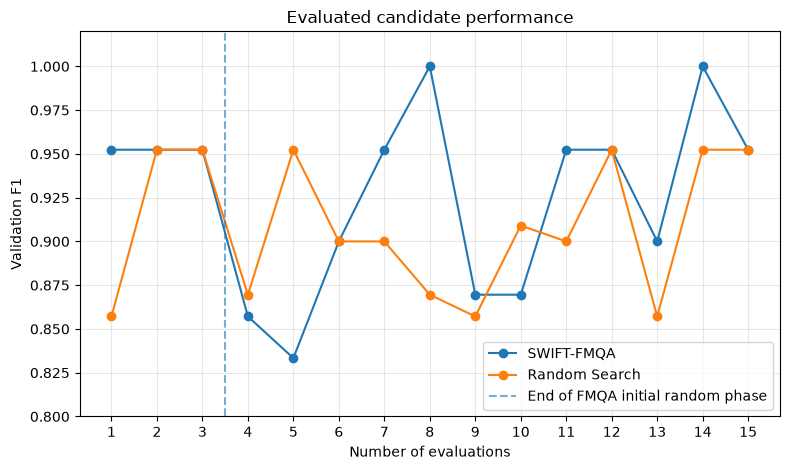

Best result
SWIFT-FMQA : F1=1.000
Random Search: F1=0.952


In [23]:
plt.figure(figsize=(8, 4.8))

# F1 actually obtained at each evaluation
plt.plot(
    fmqa_history["evaluation"],
    fmqa_history["f1"],
    marker="o",
    label="SWIFT-FMQA",
)

plt.plot(
    random_history["evaluation"],
    random_history["f1"],
    marker="o",
    label="Random Search",
)

# Mark the end of the 3 initial random evaluations of SWIFT-FMQA
plt.axvline(
    N_FMQA_INITIAL_RANDOM + 0.5,
    linestyle="--",
    alpha=0.6,
    label="End of FMQA initial random phase",
)

plt.xlabel("Number of evaluations")
plt.ylabel("Validation F1")
plt.title("Evaluated candidate performance")

plt.xticks(range(1, 16))
plt.ylim(0.80, 1.02)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Best result
fmqa_best = fmqa_history.loc[
    fmqa_history["f1"].idxmax()
]

random_best = random_history.loc[
    random_history["f1"].idxmax()
]

print("Best result")
print(
    f"SWIFT-FMQA : F1={fmqa_best['f1']:.3f}"
)

print(
    f"Random Search: F1={random_best['f1']:.3f}"
)

### 7.5 Test evaluation with the setting chosen by SWIFT-FMQA (for checking the search result)

From the SWIFT-FMQA search results, we select the
parameter setting with the highest Validation F1.

We run anomaly detection on the Test data with that setting,
and check how it differs from the baseline settings used in Chapter 6.

**This evaluation is only for checking the search result.**
Since we have already looked at the Test results in Chapter 6,
we do not reselect the parameter settings or the threshold based on the Test results here.
The final performance of the baseline settings is the result of Chapter 6,
and the result here is only a reference value for comparison with the setting found by SWIFT-FMQA.




In [24]:
# Get the best setting found by SWIFT-FMQA
fmqa_best = fmqa_history.loc[
    fmqa_history["f1"].idxmax()
]

best_params = fmqa_best["params"]

print("Best parameters found by SWIFT-FMQA:")
print(best_params)
print(f"Best Validation F1: {fmqa_best['f1']:.3f}")


# Preprocess with the best parameters
(
    train_fit_best,
    calibration_best,
    _,
    _,
) = get_preprocessed(
    best_params["pca_dim"]
)

# Select the samples used for clustering
best_subset_indices = select_representative_indices(
    len(train_fit_best),
    best_params["n_representative_samples"],
    HANDSON_SEED,
)

best_subset_features = train_fit_best[
    best_subset_indices
]

# Cluster with qklearn
best_labels, _, _, _, _ = run_qklearn(
    best_subset_features,
    n_clusters=best_params["n_clusters"],
    metric=pipeline_config["qklearn_metric"],
    scaling=pipeline_config["qklearn_scaling"],
)

# Representative points
best_reps = representative_points(
    best_subset_features,
    np.asarray(best_labels),
    best_params["center_mode"],
    pipeline_config["scoring_metric"],
)

# Determine the threshold from calibration
best_calibration_scores = cdist(
    calibration_best,
    best_reps,
    metric=pipeline_config["scoring_metric"],
).min(axis=1)

best_threshold = float(
    np.percentile(
        best_calibration_scores,
        pipeline_config["threshold_param"],
    )
)

# Preprocess the Test data with the best PCA dimension as well
test_good_best = raw_features(
    rows_df,
    "test_good",
    features_by_id,
)

test_anomaly_best = raw_features(
    rows_df,
    "test_anomaly",
    features_by_id,
)

test_good_best = scaler.transform(
    test_good_best
)

test_anomaly_best = scaler.transform(
    test_anomaly_best
)

# Re-create the best PCA under the same conditions as get_preprocessed
train_raw_best = raw_features(
    rows_df,
    "train_fit_good",
    features_by_id,
)

pca_best = PCA(
    n_components=best_params["pca_dim"],
    whiten=pipeline_config["pca_whiten"],
    random_state=0,
).fit(
    scaler.transform(train_raw_best)
)

test_good_best = pca_best.transform(
    test_good_best
)

test_anomaly_best = pca_best.transform(
    test_anomaly_best
)

test_features_best = np.concatenate([
    test_good_best,
    test_anomaly_best,
])

test_labels_best = np.concatenate([
    np.zeros(len(test_good_best), dtype=int),
    np.ones(len(test_anomaly_best), dtype=int),
])

# Anomaly scores of Test
test_scores_best = cdist(
    test_features_best,
    best_reps,
    metric=pipeline_config["scoring_metric"],
).min(axis=1)

test_predictions_best = (
    test_scores_best > best_threshold
).astype(int)

tn_b, fp_b, fn_b, tp_b = confusion_matrix(
    test_labels_best,
    test_predictions_best,
    labels=[0, 1],
).ravel()

best_test_f1 = f1_score(
    test_labels_best,
    test_predictions_best,
    zero_division=0,
)

best_test_recall = recall_score(
    test_labels_best,
    test_predictions_best,
    zero_division=0,
)

best_test_precision = precision_score(
    test_labels_best,
    test_predictions_best,
    zero_division=0,
)

print()
print(f"threshold: {best_threshold:.3f}")
print(f"TP={tp_b}, FP={fp_b}, TN={tn_b}, FN={fn_b}")
print(f"Recall:    {best_test_recall:.3f}")
print(f"Precision: {best_test_precision:.3f}")
print(f"F1:        {best_test_f1:.3f}")

Best parameters found by SWIFT-FMQA:
{'pca_dim': 32, 'center_mode': 'medoid', 'n_clusters': 3, 'n_representative_samples': 30}
Best Validation F1: 1.000



threshold: 26.548
TP=8, FP=0, TN=10, FN=2
Recall:    0.800
Precision: 1.000
F1:        0.889


## 8. Summary

In this tutorial we used MVTec AD image data
to perform clustering and anomaly detection with qklearn.

We also looked at the differences when the same QUBO is solved with Amplify and Neal,
and ran a hyperparameter search with SWIFT-FMQA.

Finally, we compared it with Random Search
and saw that the candidates and results selected differ depending on the search method.
